In [9]:
import random
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch 
import torch.nn as nn
import torch.optim as optim 

In [10]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )
    
    def forward(self, x):
        return self.fc(x)

In [ ]:
# [SỬA] Thêm deque (bộ nhớ replay) và copy (tạo target network)
from collections import deque
import copy

# [SỬA] Bỏ render_mode="human": vẽ từng bước làm huấn luyện rất chậm. Chỉ cần render khi muốn xem agent chơi.
env = gym.make("CartPole-v1")

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

model = QNetwork(state_dim, action_dim)
optimizer = optim.Adam(model.parameters(), lr=0.001)
# [SỬA] MSELoss -> SmoothL1Loss (Huber): ít bị "nổ" khi target có giá trị lệch lớn, học ổn định hơn.
criterion = nn.SmoothL1Loss()

# [THÊM] Target network: bản sao của model, chỉ cập nhật định kỳ.
# Lý do: trước đây target tính bằng chính model đang học nên mục tiêu thay đổi liên tục (đuổi theo cái bóng của mình).
target_model = copy.deepcopy(model)
target_model.eval()
target_update_every = 200   # Cứ 200 bước thì copy trọng số model -> target_model

# [THÊM] Replay buffer: lưu kinh nghiệm cũ rồi lấy ngẫu nhiên ra học.
# Lý do: các bước liên tiếp rất giống nhau (tương quan cao); lấy ngẫu nhiên giúp phá tương quan và tái sử dụng dữ liệu.
replay_buffer = deque(maxlen=10000)
batch_size = 64

episodes = 500          # Số ván chơi huấn luyện
gamma = 0.99            # Hệ số chiết khấu tương lai
epsilon = 1.0           # Tỷ lệ khám phá (exploration rate)
epsilon_decay = 0.98    # [SỬA] 0.99 -> 0.98: giảm nhanh hơn để với 200 episode, agent kịp khai thác (eps cuối ≈ 0.02)
epsilon_min = 0.01

scores = []
total_steps = 0

print("Training...")

for e in range(episodes):
    state, _ = env.reset()
    total_reward = 0
    done = False
    
    while not done:
        # Chọn hành động theo Epsilon-Greedy (Exploration and Exploitation)
        if random.random() < epsilon:
            action = env.action_space.sample() # Mò ngẫu nhiên
        else:
            with torch.no_grad():
                state_t = torch.FloatTensor(state).unsqueeze(0)
                q_values = model(state_t)
                action = torch.argmax(q_values).item() # Dùng argmax để lựa chọn hành động 
                
        # Thực hiện hành động trong env
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        
        # [THÊM] Lưu kinh nghiệm vào buffer.
        # [SỬA] Lưu `terminated` (gậy đổ thật) thay vì `done`: nếu chỉ hết giờ (truncated, 500 bước)
        # thì tương lai vẫn còn giá trị, không được coi là trạng thái kết thúc khi tính target.
        replay_buffer.append((state, action, reward, next_state, float(terminated)))
        
        state = next_state
        total_reward += reward
        total_steps += 1
        
        # [SỬA] Chỉ học khi buffer đủ dữ liệu, và học theo BATCH ngẫu nhiên thay vì 1 mẫu duy nhất.
        if len(replay_buffer) >= batch_size:
            batch = random.sample(replay_buffer, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)
            
            states_t = torch.FloatTensor(np.array(states))
            actions_t = torch.LongTensor(actions).unsqueeze(1)
            rewards_t = torch.FloatTensor(rewards)
            next_states_t = torch.FloatTensor(np.array(next_states))
            dones_t = torch.FloatTensor(dones)
            
            # Thiết kế nhãn mục tiêu (Target) để cập nhật Q-value
            # [SỬA] Dùng target_model (không phải model) để tính max Q của trạng thái kế tiếp
            with torch.no_grad():
                max_next_q = target_model(next_states_t).max(dim=1)[0]
                target = rewards_t + gamma * max_next_q * (1 - dones_t)
            
            # [SỬA] Lấy Q của đúng action đã chọn cho cả batch bằng gather.
            # (Dòng cũ đặt sai ngoặc nên lỗi; ở đây model(states_t) trả về (batch, 2), gather chọn cột = action)
            current_q = model(states_t).gather(1, actions_t).squeeze(1)
            
            loss = criterion(current_q, target)
            
            # Cập nhật trọng số Neuron bằng Backpropagation
            optimizer.zero_grad()
            loss.backward()
            # [THÊM] Cắt gradient để tránh một bước cập nhật quá lớn làm mạng lệch hướng
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()
        
        # [THÊM] Định kỳ copy trọng số sang target network
        if total_steps % target_update_every == 0:
            target_model.load_state_dict(model.state_dict())
    
    # Giảm epsilon sau mỗi tập: ban đầu khám phá nhiều, về sau khai thác nhiều hơn
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    scores.append(total_reward)
    
    print(f"Episode: {e+1}/{episodes} | Score: {total_reward} | Epsilon: {epsilon:.2f}")

env.close()


Training...
Episode: 1/500 | Score: 20.0 | Epsilon: 0.98
Episode: 2/500 | Score: 15.0 | Epsilon: 0.96
Episode: 3/500 | Score: 30.0 | Epsilon: 0.94
Episode: 4/500 | Score: 19.0 | Epsilon: 0.92
Episode: 5/500 | Score: 20.0 | Epsilon: 0.90
Episode: 6/500 | Score: 26.0 | Epsilon: 0.89
Episode: 7/500 | Score: 26.0 | Epsilon: 0.87
Episode: 8/500 | Score: 9.0 | Epsilon: 0.85
Episode: 9/500 | Score: 14.0 | Epsilon: 0.83
Episode: 10/500 | Score: 10.0 | Epsilon: 0.82
Episode: 11/500 | Score: 22.0 | Epsilon: 0.80
Episode: 12/500 | Score: 31.0 | Epsilon: 0.78
Episode: 13/500 | Score: 23.0 | Epsilon: 0.77
Episode: 14/500 | Score: 14.0 | Epsilon: 0.75
Episode: 15/500 | Score: 14.0 | Epsilon: 0.74
Episode: 16/500 | Score: 10.0 | Epsilon: 0.72
Episode: 17/500 | Score: 14.0 | Epsilon: 0.71
Episode: 18/500 | Score: 13.0 | Epsilon: 0.70
Episode: 19/500 | Score: 9.0 | Epsilon: 0.68
Episode: 20/500 | Score: 15.0 | Epsilon: 0.67
Episode: 21/500 | Score: 10.0 | Epsilon: 0.65
Episode: 22/500 | Score: 11.0 | E

KeyboardInterrupt: 

: 

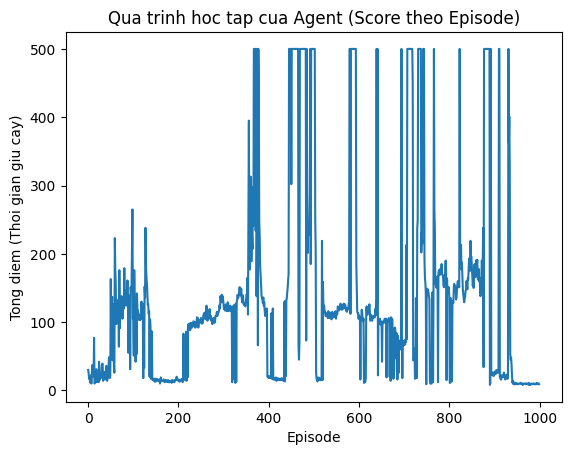

In [12]:
plt.plot(scores)
plt.title("Qua trinh hoc tap cua Agent (Score theo Episode)")
plt.xlabel("Episode")
plt.ylabel("Tong diem (Thoi gian giu cay)")
plt.show()

In [14]:
# Đánh giá sau huấn luyện: chạy policy THUẦN GREEDY (epsilon = 0, không khám phá, không học)
def evaluate(model, n_episodes=20, render=False):
    # env cũ đã bị env.close() ở cell huấn luyện nên tạo env mới.
    # render=True sẽ mở cửa sổ để xem agent chơi; render=False thì chạy nhanh.
    eval_env = gym.make("CartPole-v1", render_mode="human" if render else None)
    model.eval()                       # chuyển sang chế độ đánh giá
    results = []
    for _ in range(n_episodes):
        state, _ = eval_env.reset()
        done, total = False, 0
        while not done:
            with torch.no_grad():      # không tính gradient vì không huấn luyện
                action = model(torch.FloatTensor(state).unsqueeze(0)).argmax().item()
            state, reward, terminated, truncated, _ = eval_env.step(action)
            done = terminated or truncated
            total += reward
        results.append(total)
    eval_env.close()
    model.train()
    return results

# 1) Đo định lượng: 20 ván, không render
results = evaluate(model, n_episodes=20)
print(f"Điểm trung bình: {np.mean(results):.1f} | Min: {min(results)} | Max: {max(results)}")
print(f"Số ván đạt 500 điểm: {sum(r >= 500 for r in results)}/{len(results)}")

# 2) Lưu model để dùng lại, không cần train lại
torch.save(model.state_dict(), "cartpole_dqn.pth")

# 3) Xem trực quan 3 ván (bỏ comment để chạy)
# evaluate(model, n_episodes=3, render=True)

# Nạp lại model đã lưu (ở phiên khác):
# model = QNetwork(4, 2); model.load_state_dict(torch.load("cartpole_dqn.pth"))


Điểm trung bình: 500.0 | Min: 500.0 | Max: 500.0
Số ván đạt 500 điểm: 20/20


In [15]:
# Xem agent chơi trực quan: mở cửa sổ pygame, chạy 3 ván greedy.
# Lưu ý: cửa sổ tự đóng khi xong ván cuối. Mỗi ván tối đa 500 bước (~10 giây).
evaluate(model, n_episodes=3, render=True)


[500.0, 500.0, 500.0]

# Thực nghiệm phương pháp PPO

In [1]:
import gymnasium as gym
import numpy as np 
import torch 
import torch.nn as nn 
from torch.distributions import Categorical

### Thiết lập Hyperparameter:
- T: số bước mỗi rollout
    - Là số bước agent chơi trước mỗi lần **cập nhật**
    - Quá nhỏ: ước lượng advantage nhiễu, học bị dao động
    - Quá lớn: cập nhật hiếm, học chậm
    - Bởi vậy: 2048 là mặc định của PPO gốc cho điều khiển với 1 env. Với 8 env song song, người ta dùng khoảng 128 bước mỗi env (tổng 1024)
- K: Số epochs
    - Là số lần duyệt qua cùng 2048 mẫu
    - Quá nhỏ: lãng phí dữ liệu, học chậm.
    - Quá lớn: chính sách đi xa π_cũ, nhiều mẫu bị clip, dữ liệu dần hết giá trị.
    - Đây là tham số **trực tiếp liên quan tới clip**. K càng lớn thì clip càng quan trọng.
- MB: Mini batch
    - Là số mẫu mỗi lần tính gradient
    - Quá nhỏ: gradient nhiễu. Quá lớn: ít lần cập nhật hơn
    - Phép tính: 2048 / 64 = 32 mini batch mỗi epoch, nên mỗi rollout có 10 x 32 = **320 lần cập nhật.**

- Gamma (γ) (discount)
    - Là mức độ agent quan tâm đến reward xa.
    - Các ước lượng tầm nhìn: `1 / (1 - γ)` = 100 bước. Agent "nhìn" khoảng 100 bước phía trước.
    - Lí do chọn: CartPole kéo dài đến 500 bước, và lỗi hôm nay gây thất bại sau vài chục bước. Nên yeah 0.99 là đủ. γ - 0.9 (tầm nhìn 10 bước) có thể sẽ bị quá ngắn.

- Lam (λ) (GAE)
    - Là cân bằng giữa nhiễu và tính bias khi tính advantage.
    - Gamma = 0: chỉ nhìn 1 bước. Nhiễu thấp, bias cao (phụ thuộc vào critic còn sai)
    - Gamma = 1: nhìn đến cuối episode. Bias thấp, nhiễu cao.
    - 0.95 là thỏa hiệp phổ biến về ý nghĩa. Nên 0.95 được cho là giá trị tốt nhất.

- ε = 0.2 (clip)
    - Là `ratio` chỉ được lệch tối đa rất an toàn nhưng chậm.
    - Quá nhỏ: cập nhật rất an toàn nhưng chậm.
    - Quá lớn: clip gần như không có tác dụng, mất ổn định.
    - 0.2 là giá trị của bài báo gốc. Tham số này được nghiên cứu là ít nhạy hơn các tham số khác.

- LR
    - Là tham số **nhạy nhất** trong bảng này. Quá lớn thì `clipfrac` và `kl` tăng vọt, reward sập. Quá nhỏ thì học rất chậm.
    - 3e-4 là giá trị mặc định rất phổ biến của Adam.
    - Nheieuf bản cài đặt giảm LR dần về 0 trong quá trình huấn luyện. Code hiện tại **không** làm vậy, để đơn giản hóa quá trình học.

- C1 = 0.5 (hệ số value loss)
    - Cân bằng giữa việc học chính sách và việc học critic.
    - Khi hai mạng riêng, C1 gần như không ảnh hưởng gì, vì hai mạng không chia sẻ trọng số. Nó chỉ quan trọng khi dùng thân chung.

- C2 = 0.01 (hệ số entropy)
    - Là gì: mức thưởng cho việc giữ chính sách ngẫu nhiên.
    - Quá nhỏ: entropy rơi về 0 sớm, agent ngừng khám phá.
    - Quá lớn: agent chơi quá ngẫu nhiên, không hội tụ.
    - Với CartPole, 0.0 đến 0.01 đều chạy được.

- Gradient clip và Adam eps 1e-5
    - Gradient clip giới hạn độ tổng của gradient, tránh một bước cập nhật quá mạnh.
    - Cả hai là chi tiết cài đặt phổ biến từ OpenAI Baselines. Bạn có thể giữ nguyên.


In [2]:
# ---- Setup Neuron Network ----
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, n_actions):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, n_actions)
        )
        self.critic = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        dist = Categorical(logits=self.actor(x)) # Softmax dist
        value = self.critic(x).squeeze(-1)
        return dist, value

In [3]:
import copy

# ---- Hyperparameter----
T, K, MB = 2048, 10, 64
GAMMA, LAM, EPS = 0.99, 0.95, 0.2
LR, C1, C2 = 3e-4, 0.5, 0.01
TOTAL_STEPS = 100_000


env = gym.make("CartPole-v1")
model = ActorCritic(env.observation_space.shape[0], env.action_space.n)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, eps=1e-5)

state, _ = env.reset(seed=0)
ep_total_reward, ep_return = 0.0, []
n_updates = TOTAL_STEPS // T
print("N Updates: ", n_updates)

best_avg = -float("inf")
log = {"step": [], "avg_ret": [], "ent": [], "kl": [], "clipfrac": [], "v_loss": []}
ep_log = []   # (số bước tại lúc episode kết thúc, return của episode)


for update in range(n_updates):
    # ==== Pha 1: thu dữ liệu bằng π_cũ ====
    B_state = torch.zeros(T, 4)
    B_action = torch.zeros(T, dtype=torch.long)
    B_logp = torch.zeros(T)
    B_reward = torch.zeros(T)
    B_done = torch.zeros(T)
    B_value = torch.zeros(T)
    
    for t in range(T):
        state = torch.as_tensor(state, dtype=torch.float32)
        with torch.no_grad():
            dist, value = model(state)
            action = dist.sample() # Lấy ra action theo softmax dist,
            # hành động này thay vì Epsilon
            logp = dist.log_prob(action) # Đánh giá mức độ tự tin
            # Tính logarit xác suất của hành động thực tế vừa chọn. (Đánh giá mức độ tự tin)
        
        next_state, reward, terminated, truncated, _ = env.step(action.item())
        ep_total_reward += reward
        
        # Nếu bị cắt vì hết thời gian: bootstrap bằng V(s_cuối)
        if truncated and not terminated:
            with torch.no_grad():
                _, v_last = model(torch.as_tensor(next_state, dtype=torch.float32))
            reward = reward + GAMMA * v_last.item()
        
        done = terminated or truncated
        B_state[t], B_action[t], B_logp[t] = state, action, logp
        B_reward[t], B_done[t], B_value[t] = reward, float(done), value
        
        state = next_state
        if done:
            ep_return.append(ep_total_reward)
            ep_log.append((update * T + t + 1, ep_total_reward))
            ep_total_reward = 0.0
            state, _ = env.reset()
    # ==== Pha 2: GAE (đi ngược) ====
    with torch.no_grad():
        _, last_value = model(torch.as_tensor(state, dtype=torch.float32))
    advantage = torch.zeros(T)
    gae = 0.0
    for t in reversed(range(T)):
        next_value = last_value if t == T - 1 else B_value[t + 1]
        nonterm = 1.0 - B_done[t]
        delta = B_reward[t] + GAMMA * next_value * nonterm - B_value[t]
        gae = delta + GAMMA * LAM * nonterm * gae
        advantage[t] = gae
        
    target = advantage + B_value # target cho critic
    advantage = (advantage - advantage.mean()) / (advantage.std() + 1e-8) # chuẩn hóa

    # ==== Pha 3: cập nhật K epochs ====
    for _ in range(K):
        perm = torch.randperm(T)
        for i in range(0, T, MB):
            idx = perm[i:i + MB]
            dist, v = model(B_state[idx])
            logp = dist.log_prob(B_action[idx])
            ratio = (logp - B_logp[idx]).exp()

            pg_loss = -torch.min(
                ratio * advantage[idx],
                ratio.clamp(1 - EPS, 1 + EPS) * advantage[idx]).mean()
            v_loss = (v - target[idx]).pow(2).mean()
            ent = dist.entropy().mean()
            loss = pg_loss + C1 * v_loss - C2 * ent

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()
            
    with torch.no_grad():
        approx_kl = (B_logp[idx] - logp).mean().item()
        clipfrac = ((ratio - 1).abs() > EPS).float().mean().item()
    avg = np.mean(ep_return[-20:]) if ep_return else 0
    
    log["step"].append((update + 1) * T)
    log["avg_ret"].append(avg)
    log["ent"].append(ent.item())
    log["kl"].append(approx_kl)
    log["clipfrac"].append(clipfrac)
    log["v_loss"].append(v_loss.item())
    
    if avg > best_avg:
        best_avg = avg
        torch.save(model.state_dict(), "ppo_cartpole_best.pt")
        
    print(f"upd {update:3d} | steps {(update+1)*T:6d} | avg_ret {avg:6.1f} | "
          f"ent {ent.item():.3f} | kl {approx_kl:.4f} | clipfrac {clipfrac:.2f}")
    
torch.save(model.state_dict(), "ppo_cartpole_last.pt")

N Updates:  48
upd   0 | steps   2048 | avg_ret   19.3 | ent 0.688 | kl 0.0217 | clipfrac 0.19
upd   1 | steps   4096 | avg_ret   24.1 | ent 0.678 | kl 0.0294 | clipfrac 0.23
upd   2 | steps   6144 | avg_ret   34.7 | ent 0.645 | kl 0.0175 | clipfrac 0.19
upd   3 | steps   8192 | avg_ret   77.3 | ent 0.605 | kl 0.0250 | clipfrac 0.20
upd   4 | steps  10240 | avg_ret   88.8 | ent 0.601 | kl -0.0156 | clipfrac 0.06
upd   5 | steps  12288 | avg_ret  127.9 | ent 0.573 | kl -0.0043 | clipfrac 0.00
upd   6 | steps  14336 | avg_ret  155.1 | ent 0.572 | kl 0.0362 | clipfrac 0.12
upd   7 | steps  16384 | avg_ret  198.2 | ent 0.604 | kl -0.0006 | clipfrac 0.05
upd   8 | steps  18432 | avg_ret  244.9 | ent 0.560 | kl 0.0086 | clipfrac 0.05
upd   9 | steps  20480 | avg_ret  289.1 | ent 0.562 | kl -0.0044 | clipfrac 0.03
upd  10 | steps  22528 | avg_ret  318.6 | ent 0.545 | kl -0.0168 | clipfrac 0.03
upd  11 | steps  24576 | avg_ret  333.9 | ent 0.553 | kl 0.0212 | clipfrac 0.22
upd  12 | steps  266

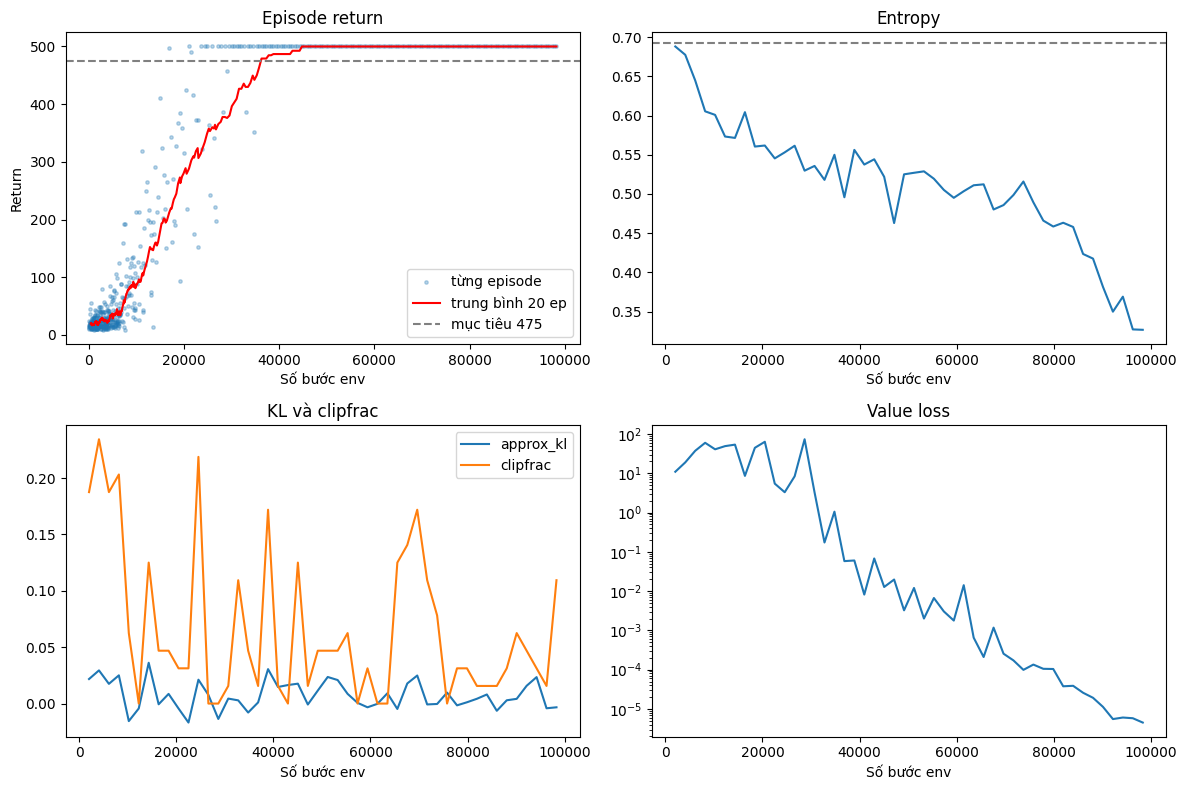

In [4]:
import matplotlib.pyplot as plt

def plot_training(log, ep_log, window=20):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # 1. Return: điểm mờ = từng episode, đường đậm = trung bình trượt
    steps, rets = zip(*ep_log)
    axes[0, 0].scatter(steps, rets, s=6, alpha=0.3, label="từng episode")
    if len(rets) >= window:
        ma = np.convolve(rets, np.ones(window) / window, mode="valid")
        axes[0, 0].plot(steps[window - 1:], ma, color="red", label=f"trung bình {window} ep")
    axes[0, 0].axhline(475, ls="--", color="gray", label="mục tiêu 475")
    axes[0, 0].set(title="Episode return", xlabel="Số bước env", ylabel="Return")
    axes[0, 0].legend()

    # 2. Entropy
    axes[0, 1].plot(log["step"], log["ent"])
    axes[0, 1].axhline(np.log(2), ls="--", color="gray")   # entropy tối đa của 2 action
    axes[0, 1].set(title="Entropy", xlabel="Số bước env")

    # 3. KL và clipfrac
    axes[1, 0].plot(log["step"], log["kl"], label="approx_kl")
    axes[1, 0].plot(log["step"], log["clipfrac"], label="clipfrac")
    axes[1, 0].set(title="KL và clipfrac", xlabel="Số bước env")
    axes[1, 0].legend()

    # 4. Value loss
    axes[1, 1].plot(log["step"], log["v_loss"])
    axes[1, 1].set(title="Value loss", xlabel="Số bước env", yscale="log")

    plt.tight_layout()
    plt.savefig("ppo_cartpole_curves.png", dpi=150)
    plt.show()

plot_training(log, ep_log)

In [5]:
def watch(model, episodes=5, greedy=True):
    env = gym.make("CartPole-v1", render_mode="human")
    for ep in range(episodes):
        state, _ = env.reset()
        total, done = 0.0, False
        while not done:
            s = torch.as_tensor(state, dtype=torch.float32)
            with torch.no_grad():
                dist, _ = model(s)
                action = dist.probs.argmax() if greedy else dist.sample()
            state, r, terminated, truncated, _ = env.step(action.item())
            total += r
            done = terminated or truncated
        print(f"episode {ep + 1}: return = {total}")
    env.close()

# Nạp model đã lưu và xem
best = ActorCritic(4, 2)
best.load_state_dict(torch.load("ppo_cartpole_best.pt"))
best.eval()
watch(best, episodes=5, greedy=True)

episode 1: return = 500.0
episode 2: return = 500.0
episode 3: return = 500.0
episode 4: return = 500.0
episode 5: return = 500.0
